In [43]:
using Plots
using LaTeXStrings
using Colors
using OdsIO
using DataFrames

# file="../Test Systems/Nordic60/Result/Iter_Report/SCOPF(3,3)"
# data = ods_read(file)
Path="TESTIFY/Programming/Arman/ST-SCOPF-new/Test Systems/Nordic60/Result/Iter_Report"
num_initial_points = 5  # 5 different starting points
data=[DataFrame() for i in num_initial_points]
data[1] = ods_read(Path*"/SCOPF_3_3",retType= "DataFrame")
data[2] = ods_read(Path*"/SCOPF_4_3",retType= "DataFrame")
data[3] = ods_read(Path*"/SCOPF_5_3",retType= "DataFrame")
data[4] = ods_read(Path*"/SCOPF_6_3",retType= "DataFrame")
data[5] = ods_read(Path*"/SCOPF_7_3",retType= "DataFrame")




LoadError: BoundsError: attempt to access 0-dimensional Array{DataFrame, 0} at index [2]

In [40]:
DataFrame()

0×0 DataFrame

In [35]:
data1.Time[2:end-1]+data1.Res_Time[2:end-1]

11-element Vector{Real}:
   0
  28.273198127746582
  46.73807907104492
  58.79662227630615
  68.08494210243225
  78.951003074646
  88.74251317977905
  97.82737898826599
 107.19262599945068
 116.01194596290588
 125.21493601799011

In [36]:
function ctime(data1)
    return data1.Time[2:end-1]+data1.Res_Time[2:end-1]
end

cumulative_time=[ctime(data[1])]


11-element Vector{Real}:
   0
  28.273198127746582
  46.73807907104492
  58.79662227630615
  68.08494210243225
  78.951003074646
  88.74251317977905
  97.82737898826599
 107.19262599945068
 116.01194596290588
 125.21493601799011

In [ ]:

# Example data
iterations = 1:10  # Assume 10 iterations



for i in num_initial_points
    
    
# Simulated data for each initial point
cumulative_time = [cumsum(rand(1:5, 10)) for _ in 1:num_initial_points]  # Cumulative time
infeasibility = [exp.(-0.5 .* iterations) .+ 0.01 .* rand(10) for _ in 1:num_initial_points]  # Decreasing infeasibility
optimality_gap = [reverse(log.(1 .+ iterations .+ 0.1 .* rand(10))) for _ in 1:num_initial_points]  # Optimality gap

# Plot settings
palette = distinguishable_colors(num_initial_points, [RGB(1,1,1), RGB(0,0,0)])
plot_title = ["Cumulative Time Spent", "Infeasibility at Iterations", "Optimality Gap"]

# Create subplots
p1 = plot(title="Cumulative Time Spent in Optimizer", xlabel="Iteration", ylabel="Cumulative Time (s)", 
    legend=:topleft, size=(800, 400), grid=:on)
for i in 1:num_initial_points
    plot!(p1, iterations, cumulative_time[i], lw=2, color=palette[i], label="Init Point $i")
end

p2 = plot(title="Infeasibility During Iterations", xlabel="Iteration", ylabel="Infeasibility",
    legend=:topright, size=(800, 400), grid=:on)
for i in 1:num_initial_points
    plot!(p2, iterations, infeasibility[i], lw=2, color=palette[i], label="Init Point $i")
end

p3 = plot(title="Optimality Gap Change", xlabel="Iteration", ylabel="Optimality Gap",
    legend=:topright, size=(800, 400), grid=:on)
for i in 1:num_initial_points
    plot!(p3, iterations, optimality_gap[i], lw=2, color=palette[i], label="Init Point $i")
end

# Combine subplots
final_plot = plot(p1, p2, p3, layout=(1,3), size=(1200, 400), dpi=300)

# Save to file for IEEE paper
savefig("optimization_iterations_results.png")

display(final_plot)

In [28]:
cumulative_time

5-element Vector{Vector{Int64}}:
 [2, 3, 8, 13, 15, 17, 19, 20, 24, 29]
 [1, 3, 8, 12, 16, 20, 25, 28, 33, 38]
 [4, 6, 9, 11, 16, 21, 24, 26, 31, 36]
 [1, 4, 6, 8, 9, 12, 14, 15, 19, 22]
 [3, 8, 11, 12, 16, 20, 23, 26, 29, 34]

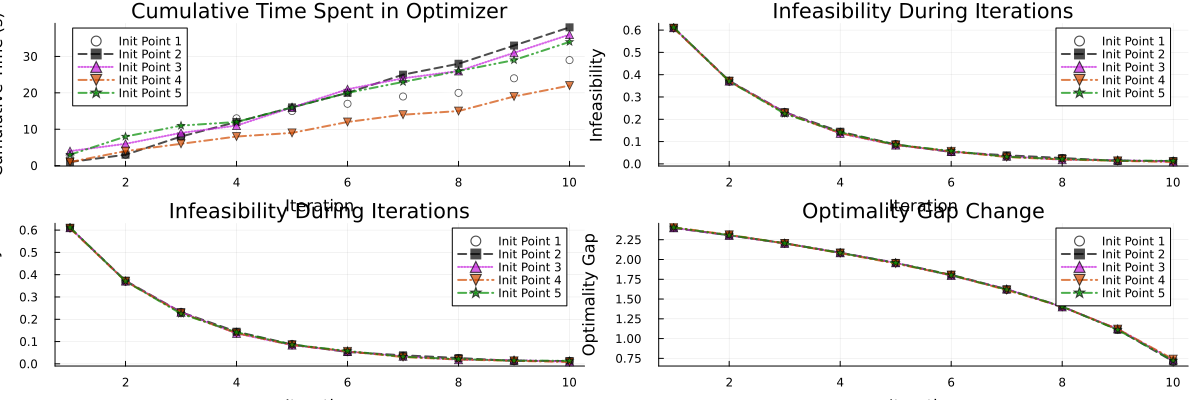

In [8]:
using Plots
using LaTeXStrings
using Colors

# Example data
iterations = 1:10  # Assume 10 iterations
num_initial_points = 5  # 5 different starting points

# Simulated data
cumulative_time = [cumsum(rand(1:5, 10)) for _ in 1:num_initial_points]
infeasibility = [exp.(-0.5 .* iterations) .+ 0.01 .* rand(10) for _ in 1:num_initial_points]
optimality_gap = [reverse(log.(1 .+ iterations .+ 0.1 .* rand(10))) for _ in 1:num_initial_points]

# Distinctive Colors and Line Styles
palette = distinguishable_colors(num_initial_points, [RGB(1,1,1), RGB(0,0,0)])
line_styles = [:solid, :dash, :dot, :dashdot, :dashdotdot]
markers = [:circle, :square, :utriangle, :dtriangle, :star5]

# Cumulative Time Plot
p1 = plot(title="Cumulative Time Spent in Optimizer", xlabel="Iteration", ylabel="Cumulative Time (s)",
    legend=:topleft, grid=:on, size=(800, 400))
for i in 1:num_initial_points
    plot!(p1, iterations, cumulative_time[i], lw=2, color=palette[i], label="Init Point $i",
          linestyle=line_styles[i], marker=markers[i], alpha=0.7)
end

# Infeasibility Plot
p2 = plot(title="Infeasibility During Iterations", xlabel="Iteration", ylabel="Infeasibility",
    legend=:topright, grid=:on, size=(800, 400))
for i in 1:num_initial_points
    plot!(p2, iterations, infeasibility[i], lw=2, color=palette[i], label="Init Point $i",
          linestyle=line_styles[i], marker=markers[i], alpha=0.7)
end

p3 = plot(title="Infeasibility During Iterations", xlabel="Iteration", ylabel="Infeasibility",
    legend=:topright, grid=:on, size=(800, 400))
for i in 1:num_initial_points
    plot!(p3, iterations, infeasibility[i], lw=2, color=palette[i], label="Init Point $i",
          linestyle=line_styles[i], marker=markers[i], alpha=0.7)
end

# Optimality Gap Plot
p4 = plot(title="Optimality Gap Change", xlabel="Iteration", ylabel="Optimality Gap",
    legend=:topright, grid=:on, size=(800, 400))
for i in 1:num_initial_points
    plot!(p4, iterations, optimality_gap[i], lw=2, color=palette[i], label="Init Point $i",
          linestyle=line_styles[i], marker=markers[i], alpha=0.7)
end

# Combine Subplots
final_plot = plot(p1, p2, p3, p4, layout=(2,2), size=(1200, 400), dpi=300)

# Save the Figure
savefig("optimization_iterations_results.png")
display(final_plot)


In [10]:
pwd()

"/home/zarrin/TESTIFY/Programming/Arman/ST-SCOPF-new/src"

In [18]:
cd()